<a href="https://colab.research.google.com/github/tomviolin/FreshwateRWebSite/blob/main/r2u_ULTRA_FAST_PACKAGE_LOADING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **FreshwateR UNIT TWO: Data Wrangling**

## **r2u fast R package loading in Colab**

<font color="red">**Please run this and only this cell.**</font>

###<font color="red">YOU ***MAY*** get a warning that **This notebook was not authored by Google**.  It's ok to respond affirmatively and go on.


In [115]:
# run this cell to get FAST loading with the install.packages(...) function.
install.packages <- function(pkgs, ...) {
  for (pkg in pkgs) {
    system(paste0("sudo apt-get install -y -q r-cran-", tolower(pkg)),
           ignore.stdout = TRUE, ignore.stderr = TRUE)
  }
}

# **Tidyverse**
### The ***tidyverse*** is a set of R functions that work together well and have some pretty clever ways of doing things.

In [ ]:
## Run the code in this cell to enable the Tidyverse in Colab.

install.packages("tidyverse")
library(tidyverse)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


#**Data Wrangling!**
Now it's time to start ***data wrangling***.   This describes the process of examining and turning over your data, to gauge its size, range of values, and so on.

## **Obtain the data**

### **Gapminder** is a good example dataset, and obtaining it is easy, because it exists as an R installable package.

***Gapminder*** is an independent Swedish foundation with no political, religious, or economic affiliations. *__Gapminder__* identifies systematic misconceptions about important global trends and proportions and uses reliable data to develop easy to understand teaching materials to rid people of their misconceptions.



In [ ]:
### run this cell to obtain the gapminder dataset

install.packages("gapminder")
library(gapminder)

###**head()**
This shows the column headers, types, and the first few values in the dataset.

In [ ]:
# run this cell to get column headers, types, and the first few values in the dataset.

head(gapminder)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Afghanistan,Asia,1957,30.332,9240934,820.8530
Afghanistan,Asia,1962,31.997,10267083,853.1007
Afghanistan,Asia,1967,34.020,11537966,836.1971
Afghanistan,Asia,1972,36.088,13079460,739.9811
Afghanistan,Asia,1977,38.438,14880372,786.1134


### Now that we have an overview of what the dataset looks like, we'll want to start looking around a bit.

##**filter()**
This applies a condition that each row of the dataset must satisfy for it to pass the filter.


In [122]:
# Applies a filter to the data frame.

filter(gapminder, year==2007)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,2007,43.828,31889923,974.5803
Albania,Europe,2007,76.423,3600523,5937.0295
Algeria,Africa,2007,72.301,33333216,6223.3675
Angola,Africa,2007,42.731,12420476,4797.2313
Argentina,Americas,2007,75.320,40301927,12779.3796
Australia,Oceania,2007,81.235,20434176,34435.3674
Austria,Europe,2007,79.829,8199783,36126.4927
Bahrain,Asia,2007,75.635,708573,29796.0483
Bangladesh,Asia,2007,64.062,150448339,1391.2538


##**arrange()**
This sorts the data by one of the columns. Let's try it on the <b>year</b> column.

In [125]:
# now try sorting by year

arrange(gapminder, year)

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Albania,Europe,1952,55.230,1282697,1601.0561
Algeria,Africa,1952,43.077,9279525,2449.0082
Angola,Africa,1952,30.015,4232095,3520.6103
Argentina,Americas,1952,62.485,17876956,5911.3151
Australia,Oceania,1952,69.120,8691212,10039.5956
Austria,Europe,1952,66.800,6927772,6137.0765
Bahrain,Asia,1952,50.939,120447,9867.0848
Bangladesh,Asia,1952,37.484,46886859,684.2442


# Combining data wranglers

This is ok, so far.  But notice how the fitered and arrange/sorted tables were very long to scroll through. Luckily, we have our **head()** function, so we can do this:

In [129]:
head(filter(gapminder, year==2007))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,2007,43.828,31889923,974.5803
Albania,Europe,2007,76.423,3600523,5937.0295
Algeria,Africa,2007,72.301,33333216,6223.3675
Angola,Africa,2007,42.731,12420476,4797.2313
Argentina,Americas,2007,75.320,40301927,12779.3796
Australia,Oceania,2007,81.235,20434176,34435.3674


In [130]:
# and also this!

head(arrange(gapminder, year))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Afghanistan,Asia,1952,28.801,8425333,779.4453
Albania,Europe,1952,55.230,1282697,1601.0561
Algeria,Africa,1952,43.077,9279525,2449.0082
Angola,Africa,1952,30.015,4232095,3520.6103
Argentina,Americas,1952,62.485,17876956,5911.3151
Australia,Oceania,1952,69.120,8691212,10039.5956


## **it worked, but...**

Ok so to filter and then look at the first few rows of that result, we had to do

```R
head(filter(gapminder, year==2007))
```

And to sort and then look at the first few rows, we had to do this:

```R
head(arrange(gapminder, year))
```

This approach is ok, but if things get much more complicated, we could be in trouble.

## **What if...**
What if we want to see the first few rows of all African nations sorted by population?  We'd have to:

- pick out just African nations by filtering for continent = 'Africa'
- arrange them sorted by population;
- then use head() to take the first few rows and show them.

This would like like this:

```R
head(arrange(filter(gapminder, continent=='Africa'),pop))
```


## **Not easy!**

In order to look at that line and figure out what to do, you'd need to you have to look from the ***innermost*** to ***outermost*** function calls.

head(arrange( **filter** **(** gapminder, continent=='Africa' **)**,pop))</span>

head(**arrange** **(** filter(gapminder, continent=='Africa'),pop **)** )

**head** **(** arrange(filter(gapminder, continent=='Africa'),pop) **)**
### **Confusing, isn't it? **
This is where the genius of **tidyverse** comes in.

Tidyverse introduces to R the concept of <B>THREADING</b> functions! There are two threading operators: **`%>%`** (percent-greater than sign-percent) and **`|>`** ( vertical bar-greater-than).  They allow you to "straighten out" your sequence of operations like this:

```R
head(arrange(filter(gapminder, continent=='Africa'),pop))
```

becomes

```R
gapminder |> filter(continent=='Africa`) |> arrange(pop) |> head()
```

##**Just a tad easier!**

In [132]:
head(arrange(filter(gapminder, continent=='Africa'),pop))

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Sao Tome and Principe,Africa,1952,46.471,60011,879.5836
Sao Tome and Principe,Africa,1957,48.945,61325,860.7369
Djibouti,Africa,1952,34.812,63149,2669.5295
Sao Tome and Principe,Africa,1962,51.893,65345,1071.5511
Sao Tome and Principe,Africa,1967,54.425,70787,1384.8406
Djibouti,Africa,1957,37.328,71851,2864.9691


##**So now we can do it like this:**

In [134]:
gapminder |> filter(continent=='Africa') |> arrange(pop) |> head()

country,continent,year,lifeExp,pop,gdpPercap
<fct>,<fct>,<int>,<dbl>,<int>,<dbl>
Sao Tome and Principe,Africa,1952,46.471,60011,879.5836
Sao Tome and Principe,Africa,1957,48.945,61325,860.7369
Djibouti,Africa,1952,34.812,63149,2669.5295
Sao Tome and Principe,Africa,1962,51.893,65345,1071.5511
Sao Tome and Principe,Africa,1967,54.425,70787,1384.8406
Djibouti,Africa,1957,37.328,71851,2864.9691


## **Same answer, much easier to follow code!**
It's almost like putting together Legos!

<img src="data:image/gif;base64,R0lGODlh9wDdAIABAAAAAP///yH+EUNyZWF0ZWQgd2l0aCBHSU1QACwAAAAA9wDdAAAC/oyPqcvt
D6OctNqLs968+w+G4kiW5omm6sq27gvH8kzX9o3n+s73/g8MCoclAICITNaMTGOn2VRKp04FMwPN
bo6G6/Rb5Da8EXK2ajlDweyP2BGFkA/ailptX7f3jzgc3ff293YnOHbHl8jgtwj4V2ZIdyY3h1Cp
uIL3SOloFdn42bgweXgp2YkZhljKiepp2uWaQPoaGmsbwJg6Ugib52upV4u7GoybK3t6vIvRmzwK
qDlY2QtKq6tRx+xRuEWK/TqrC35b3WwmvM3RzU2NdUlujBwvYa6+rh2eFvnMCt0vbtmEfPfe0Zu3
D9QFYgBPhUhX8BwwZQKRlapoMVDD/lyDfm2M+G+iMYDJDgarJ5KjRpQmQV5kOFLWQYiiKExcRmsY
RpcxNYpxRpChsJSQWlIE+pGnsqKukEqLmdMg0YVTlZaraPTpPH5WxviIanWYTaIEdbIEO0Nr2KtU
cdIM2Q/pPrUD6Vp9y9TnxrLyrNXVY/SqpsCJCP+bVhXv1nZ8M750urON4cPWCCueOsfZy4DsBCcF
M3kuGpP0hn4CylYn5Gh2MYX2mLmYYrg/ozpajQh3VSq72+JFPVazJ8Sdb68u+Dp4YxRo99oWWozZ
7C2eez9E9XnxrHPIkzONDoNf7+yH7k1/Ins2Wju0G5Kvue08+qD0sVmvvLxLIJvd/t+LhgecP7dI
1BokA/UXWTa/jZbdeq2URdJ9qXjnW4L/FagahiPBgeAL8uHT2Vg9EZgfHxSSSBKKJSqn4Ip7nFih
bt/I+CFnEmooGYwX0shjjz4aF6BrOsLmX1rV2bPVj0rUCIKDaxGYBJNuSPkkSlFK6M2QVdKxJJYt
FrnlKF16GWOYD12p5VlgmmkJmmk+aCGbw7n5Jn5xytmmFDiCWOeTd9Kwp1RkArGmS07yOSiLU8bW
p3QuxvhnW9cxyEWiHJr4KJEeFtoXoydEmkOg33GqHKOUmuqFp2FMmCmcoIqGEEKpOjHrEXGoSsKr
O4j6mK7BDZiRGQPWWilrvnYV/t+hcIZXxRWDaYFOsYSQKo55yhLHrLSxBiQrpcB+KwK1PICnprgs
AUtNs7Sqy25f4Zo77rU2HvtrrLN6Nmyt7k5Kbw+iyvuus8TWVsezJ/FC5RcAA8ybtgjz2nBKDINm
aXsT0/nMxXiKdVS/oV6W8MY2QgUvDnxpLPK8R1oLUasp24nkLte4/LJe5AoZZM0PN2oDZDozx/MS
Tv38adBp+Ux0Hmomi/R1a7lntAwD/6hbx3LNC2G0thjiVtclC4011VcnKbY0ZV89E8RBiFfczFOX
OLTVNAEGDNdYyz0Jyv5uli48CrUUdzUe90rysyHvCp0fZmt9duOOP06zDmQp/g555ZZfHvOYMWDO
eec5Hz351656TjrnN4RYy9FNHhlk6T72PI59FS9k6OWAkpNO1ElnCXrdWu/+w+wXjj448Nzc/mjk
xqtQ/Hc7Nr+85L7IjrvezUS/efXYnWx9GtgvUjT1TWXdfV0Kn/nOpw6NaHFORkOvyqTcFcHtUU0K
v53mAcOKMDTVkbg+nkyvZLup0wBv5qpysKBgQ2OgNmYUrf9RRILgKkquSoI64qUGaLZiVxTyti5p
dbBY9grhtz7YLmJtq4DmShsCR8Y60XGphILwGw3zRcJgtQtdOxSYw7aVl4AdQzgZKtyQTuPA+nWM
hyT0Id0IhkOH6KuCKxGi/td6hDcYmcKHFezbDWm4QyXqK4JTBKKBhPiX0nmDMmUE1xTfyLVORPCL
XFxhUjxmmReSTUbpa08XgXSrHj4xFiesoyHraEY5XPAzGKLa/DLkQMbhAYVPZM0SJ4gvSSjtYV/C
oCTHZqXTTauKidneTgYHpvW85TgHMhkUKZHIjlTLexecDziWEzdYupJJHzrcmGLnoM9R5nsL5Ncn
QUbEYRIzT7ywYtWMqEr8+amWzjRN41K3zIOFSxXkYyV4dBcRVJqgNaxcmXayOUM9ZSVzoMymDMOH
kQzGEJ3MpBikiCPNp5nJhcqj59o0ZTMX5TNl8INP+6BWNrOARJzZgmam/lxXTkwijpqbEmEuAwpR
JR00fs2UmkU1useMipSBSgxJrozk0LlZc6QsxaLa5PS6lLZ0QVj0ZwsyiNOLngt89JOaP+X5FZT+
tHwLLKhB0fnShobHphRc20AvZVOiZsKXjxwqVW8q1XowVTBI0CP6otrPbGW1D5IjFD67mjmnLeuc
IKqQQtpKmyiRbJxxMWEhDcJVKq7rraX64SWJUMOwVlFA0/JrvSzyuwA6bY72Q2sR+YXPMVbyo3ZF
rAcJlsvJNtFbUJGrnSArSzp662121M8G7bgGyY6wW6Z1o2A9FNlFCWV9ZRRkYGHCWC/qcIa+K+xT
xaojF9LWtoPc15xy/gukRDoJVUZ1QflIw1k4sq2kj2VsFLnV286qI6zQfWVt5Zhcg373tq41rBhf
69SQdVeBXyzhH0NhrNW+l4d7DO1Yv0Kz7gInkFPTJmdiGEmLNnWWeQWsoEr5zsMGL74JXt2BndNg
ES2YY4D9E46uiicM35Qx+t0qW4Wgq0OBc6G/TW88SqyUES94QR5W8Ypv2WIXv3gcMUZxhUm6VQ0X
k4NejZ6OMzHVpL5MxmsMciN392PmVdRxWQzmY+vpXCJnA7gzNV1IIydkAVZ5y48D3iS5DOaIEq1V
yvItZsNMIy8nOWKGa6fO0Lul+6aguRR255qZ41Ebs0zP6MmelFkV/uHj+TnQe/YscMHK5yfkmdBM
Y3SLDo1oOl9PsUVNdKMlDalE3/lpf76nkR0NaFB3ssGbDkupeVziU6fY0vdTdZJunEb4ddqWjXK1
/NI4Z1Yb04Ba0rWAuInpnfHaSyDkr2YhOMLcPdDYk7H1p8V1IrseUtpcnCMlcagt0noEZzqm6r1M
K10mivuGKtSheWMdaktdldrFDbdosz1aCArKUd3TIuXk6+58pzDe03XrpZOD4fDq22EDB6NeyePs
3r0m4MdWYMHfjW36xjKI4bwYw1NbbGYvRi7MHliBcV07hq17lL/GlKgHvc5ov5KvJj85yvWbyvwk
nHmzfvlNZn7pciq9EM5hwnm8GsPzOPv6Y2AJup9qvstlIz1HQ0ecTom5dKILE3tRl15av1d1q2c5
w1l3etPTHWy0fp3bLh/C2BUh50azl+rWHPNIZYrmm53d7QA6VZPR1nGgenjvc987mvwO+MDTXfDL
6zvhD494pYqgAAA7">

&nbsp;

&nbsp;

&nbsp;

## **More data wrangler tools**

In [ ]:
# sort in **descending** order

gapminder %>% arrange(desc(gdpPercap))

In [ ]:
# generate new values or modify existing ones

# modify population to be by millions
gapminder %>% mutate( pop = pop / 1000000)

In [ ]:
# add a GDP column

gapminder %>% mutate( gdp = gdpPercap * pop )

#**AND NOW FOR SOMETHING COMPLETELY DIFFERENT!**

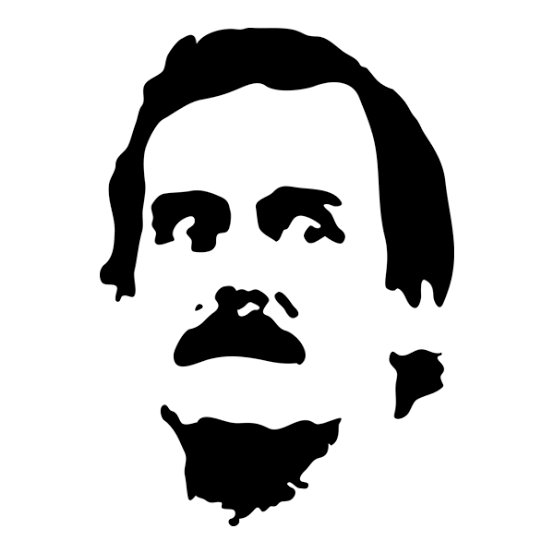

# **Just keeping you on your toes.**

## Two new wrangling functions that go together:

## **`group_by()`** and **`aggregate()`**

###**In brief:**

**`group_by()`** creates a 'bin' for each unique value in the column you specify, and then **`aggregate()`** sums, averages (mean, mode, median), takes the standard deviation of, computes the quantile of, (and other things) of any ***other*** columns besides the one(s) you have **`group`**-ed **`()`** by, and places those aggregates in each bin.

## **So for example:**

Let's say you have a table of values like this:

| Car | Year | Make | Value |
|---|---|---|---|
| Toyota | 2007 | Camry | \$ 1234.00 |
| Toyota | 2022 | Corolla | \$ 14200.00 |
| Honda | 2001  | Civic | \$ 1234.00 |
| Ford  | 1952 | Edsel | \$ 1234.00 |
| Nissan | 2005 | Sentra | \$ 500.00 |
| Datsun | 1992 | Yoga | \$ 345.00  |



**New Exercises**
- list the GDP of every country in 2007.
- List the average life expectancy across the world, **weighted by population**
